# FAERS Q3 2025 — Signal Detection Analysis
**B Aditya, SE23UCAB002 | AI in Pharmacovigilance | Assignment-1**

This notebook loads the FAERS 2025Q3 quarterly data (ASCII format), cleans and
merges the DEMO/DRUG/REAC tables, produces descriptive summaries, runs
disproportionality-based signal detection (PRR, ROR + 95% CI, Chi-square /
Fisher's exact test), and looks at time trends.

## Task 0 — Setup

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
import os

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "/Users/aditya/Desktop/sem-7/AI in pharmacovigilance/Baditya_assignment/faers_ascii_2025q3/ASCII"
FIG_DIR = "figures"
RES_DIR = "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

### A note on file encoding

FAERS quarterly ASCII files are `$`-delimited text files. FDA has historically
distributed them in **Latin-1 (`ISO-8859-1`)** encoding rather than UTF-8 —
some free-text fields (literature references, reporter names, dose comments)
contain accented characters that are not valid UTF-8 and will raise a
`UnicodeDecodeError` if read with the default encoding. We therefore load
every file with `encoding="latin-1"`. Since FDA renamed the classic `ISR`
report identifier to **`primaryid`** in recent quarters (with `caseid` +
`caseversion` underneath it), we use `primaryid` as the unique-report key
throughout this notebook, and treat it as the modern equivalent of ISR.

In [30]:
demo = pd.read_csv(f"{DATA_DIR}/DEMO25Q3.txt", sep="$", encoding="latin-1", low_memory=False)
drug = pd.read_csv(f"{DATA_DIR}/DRUG25Q3.txt", sep="$", encoding="latin-1", low_memory=False)
reac = pd.read_csv(f"{DATA_DIR}/REAC25Q3.txt", sep="$", encoding="latin-1", low_memory=False)
outc = pd.read_csv(f"{DATA_DIR}/OUTC25Q3.txt", sep="$", encoding="latin-1", low_memory=False)

print(f"DEMO: {demo.shape}")
print(f"DRUG: {drug.shape}")
print(f"REAC: {reac.shape}")
print(f"OUTC: {outc.shape}")

DEMO: (438512, 25)
DRUG: (2148451, 20)
REAC: (1535133, 4)
OUTC: (343251, 3)


## Task 1 — Load & Inspect

In [31]:
print("=== DEMO head ===")
display(demo.head())
print("\n=== DRUG head ===")
display(drug.head())
print("\n=== REAC head ===")
display(reac.head())

=== DEMO head ===


,primaryid,caseid,caseversion,i_f_code,event_dt,mfr_dt,init_fda_dt,fda_dt,rept_cod,auth_num,mfr_num,mfr_sndr,lit_ref,age,age_cod,age_grp,sex,e_sub,wt,wt_cod,rept_dt,to_mfr,occp_cod,reporter_country,occr_country
0,100289774,10028977,4,F,NaN,20250729,20140321,20250806,EXP,NaN,PHHY2014IN032993,GLAXOSMITHKLINE,"Patelln DR, Dosi VR, Shah CP, Joshi SH. Widesp...",53.0,YR,NaN,M,Y,NaN,NaN,20250805,NaN,MD,IN,IN
1,1005762123,10057621,23,F,20140204.0,20250820,20140404,20250827,EXP,NaN,CA-ROCHE-1374378,ROCHE,NaN,57.0,YR,A,M,Y,53.0,KG,20250827,NaN,CN,CA,CA
2,1006831310,10068313,10,F,20140101.0,20250908,20140409,20250911,PER,NaN,US-PFIZER INC-2014097065,PFIZER,NaN,69.0,YR,NaN,F,Y,72.0,KG,20250911,NaN,CN,US,US
3,100789263,10078926,3,F,NaN,20250918,20140415,20250922,EXP,NaN,EU-PFIZER INC-2014101534,MYLAN,C. PRIEZ-BARALLON. Quantification of Pregabali...,44.0,YR,NaN,M,Y,NaN,NaN,20250922,NaN,NaN,COUNTRY NOT SPECIFIED,EU
4,101573482,10157348,2,F,NaN,20250714,20140507,20250802,EXP,NaN,EU-AstraZeneca-2014SE30505,ALEXION PHARMACEUTICALS,"Bourneau-Martin D, Leclech C, Jamet A, Drablie...",88.0,YR,E,F,Y,NaN,NaN,20250802,NaN,NaN,EU,EU



=== DRUG head ===


,primaryid,caseid,drug_seq,role_cod,drugname,prod_ai,val_vbm,route,dose_vbm,cum_dose_chr,cum_dose_unit,dechal,rechal,lot_num,exp_dt,nda_num,dose_amt,dose_unit,dose_form,dose_freq
0,100289774,10028977,1,PS,DICLOFENAC POTASSIUM,DICLOFENAC POTASSIUM,1,NaN,UNK,NaN,NaN,Y,U,UNK,NaN,022122,NaN,NaN,NaN,NaN
1,100289774,10028977,2,C,ONDANSETRON,ONDANSETRON,1,Unknown,UNK,NaN,NaN,U,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100289774,10028977,3,C,TRAMADOL,TRAMADOL,1,Unknown,UNK,NaN,NaN,U,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100289774,10028977,4,C,ACETAMINOPHEN,ACETAMINOPHEN,1,Unknown,UNK,NaN,NaN,U,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100289774,10028977,5,C,SODIUM CHLORIDE,SODIUM CHLORIDE,1,Intravenous infusion,UNK,NaN,NaN,U,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== REAC head ===


,primaryid,caseid,pt,drug_rec_act
0,100289774,10028977,Fixed eruption,NaN
1,100289774,10028977,Stevens-Johnson syndrome,NaN
2,100289774,10028977,Toxic epidermal necrolysis,NaN
3,1005762123,10057621,Dyspnoea,NaN
4,1005762123,10057621,Hypotension,NaN


In [32]:
print("DEMO key columns:")
display(demo[["age", "age_cod", "sex", "wt"]].describe(include="all"))

print("\nDRUG key columns:")
display(drug[["role_cod", "route"]].describe(include="all"))

print("\nREAC key columns:")
display(reac[["pt"]].describe(include="all"))

DEMO key columns:


,age,age_cod,sex,wt
count,257366.000000,257378,363788,71446.000000
unique,NaN,6,2,NaN
top,NaN,YR,F,NaN
freq,NaN,251700,219604,NaN
mean,54.494261,NaN,NaN,73.510441
std,54.136576,NaN,NaN,85.221081
min,0.000000,NaN,NaN,0.000000
25%,40.000000,NaN,NaN,57.300000
50%,59.000000,NaN,NaN,70.240000
75%,71.000000,NaN,NaN,86.636000



DRUG key columns:


,role_cod,route
count,2148451,1349277
unique,5,126
top,SS,Unknown
freq,862005,611186



REAC key columns:


,pt
count,1535133
unique,13126
top,Off label use
freq,31253


In [33]:
n_demo = demo["primaryid"].nunique()
n_drug = drug["primaryid"].nunique()
n_reac = reac["primaryid"].nunique()
n_outc = outc["primaryid"].nunique()

print(f"Unique reports (primaryid) in DEMO: {n_demo:,}")
print(f"Unique reports (primaryid) in DRUG: {n_drug:,}")
print(f"Unique reports (primaryid) in REAC: {n_reac:,}")
print(f"Unique reports (primaryid) in OUTC: {n_outc:,}")

demo_ids, drug_ids, reac_ids = set(demo.primaryid), set(drug.primaryid), set(reac.primaryid)
print(f"\nIn DEMO but not in DRUG: {len(demo_ids - drug_ids):,}")
print(f"In DEMO but not in REAC: {len(demo_ids - reac_ids):,}")
print(f"In DRUG but not in DEMO: {len(drug_ids - demo_ids):,}")
print(f"In REAC but not in DEMO: {len(reac_ids - demo_ids):,}")
print(
    "\nThese mismatches are expected: a small number of cases in one table can be "
    "missing from another (e.g. a case with a coded outcome/reaction but a drug "
    "record dropped by FDA QC, or vice versa). We keep them in mind for the joins below."
)

Unique reports (primaryid) in DEMO: 438,512
Unique reports (primaryid) in DRUG: 438,512
Unique reports (primaryid) in REAC: 438,512
Unique reports (primaryid) in OUTC: 254,386

In DEMO but not in DRUG: 0
In DEMO but not in REAC: 0
In DRUG but not in DEMO: 0
In REAC but not in DEMO: 0

These mismatches are expected: a small number of cases in one table can be missing from another (e.g. a case with a coded outcome/reaction but a drug record dropped by FDA QC, or vice versa). We keep them in mind for the joins below.


## Task 2 — Clean & Merge

In [34]:
# --- Deduplicate reports ---
# Each case (caseid) can in principle appear more than once across cumulative
# submissions, with caseversion incrementing on each amendment. FDA's own
# guidance is to keep only the most recent caseversion per caseid, since a
# later version supersedes the safety information in earlier ones.
dup_cases_before = demo["caseid"].duplicated().sum()
print(f"Duplicate caseid rows in DEMO before dedup: {dup_cases_before:,}")

demo_dedup = demo.sort_values("caseversion").drop_duplicates(subset="caseid", keep="last").copy()
print(f"DEMO rows before: {len(demo):,} -> after keeping latest caseversion per case: {len(demo_dedup):,}")

keep_primaryids = set(demo_dedup["primaryid"])
drug_dedup = drug[drug["primaryid"].isin(keep_primaryids)].copy()
reac_dedup = reac[reac["primaryid"].isin(keep_primaryids)].copy()
print(f"DRUG rows after restricting to deduped reports: {len(drug_dedup):,}")
print(f"REAC rows after restricting to deduped reports: {len(reac_dedup):,}")

Duplicate caseid rows in DEMO before dedup: 0
DEMO rows before: 438,512 -> after keeping latest caseversion per case: 438,512
DRUG rows after restricting to deduped reports: 2,148,451
REAC rows after restricting to deduped reports: 1,535,133


In [35]:
# --- Standardize field names (already lowercase in this FAERS release, but
#     we normalize defensively in case of mixed-case headers / stray spaces) ---
for df in (demo_dedup, drug_dedup, reac_dedup, outc):
    df.columns = [c.strip().lower() for c in df.columns]

# --- Normalize drug names to uppercase, strip whitespace ---
drug_dedup["drugname"] = drug_dedup["drugname"].astype(str).str.strip().str.upper()
reac_dedup["pt"] = reac_dedup["pt"].astype(str).str.strip()

print(drug_dedup["drugname"].head())

0    DICLOFENAC POTASSIUM
1             ONDANSETRON
2                TRAMADOL
3           ACETAMINOPHEN
4         SODIUM CHLORIDE
Name: drugname, dtype: object


In [36]:
# --- Keep only Primary Suspect (PS) drugs for signal detection ---
# We restrict to ROLE_COD == 'PS' because disproportionality analysis (PRR/ROR)
# is meant to associate an adverse event with the drug most plausibly
# responsible for it. Concomitant ('C') and secondary-suspect ('SS')
# medications are, by definition, less likely to be the causal agent, and
# including them would dilute true signals and inflate spurious associations
# for drugs that are frequently co-prescribed rather than causal. This mirrors
# standard FAERS disproportionality-analysis practice (e.g. openFDA / EBGM,
# PRR-based screening at national pharmacovigilance centers).
print(drug_dedup["role_cod"].value_counts())

ps_drug = drug_dedup[drug_dedup["role_cod"] == "PS"].copy()
print(f"\nPS-only drug rows: {len(ps_drug):,}  |  unique PS reports: {ps_drug['primaryid'].nunique():,}")

role_cod
SS    862005
C     795993
PS    480527
I       9863
DN        63
Name: count, dtype: int64

PS-only drug rows: 480,527  |  unique PS reports: 438,512


In [37]:
# --- Merge drug (PS) and reac to build drug-ADR pair table, joined to demo ---
ps_drug_u = ps_drug[["primaryid", "caseid", "drugname"]].drop_duplicates()
reac_u = reac_dedup[["primaryid", "pt"]].drop_duplicates()

pairs = ps_drug_u.merge(reac_u, on="primaryid", how="inner")
pairs = pairs.merge(
    demo_dedup[["primaryid", "age", "age_cod", "sex", "fda_dt", "event_dt"]],
    on="primaryid",
    how="left",
)
print(f"Drug-ADR pair rows (report x PS-drug x reaction): {len(pairs):,}")
display(pairs.head())

Drug-ADR pair rows (report x PS-drug x reaction): 1,517,088


,primaryid,caseid,drugname,pt,age,age_cod,sex,fda_dt,event_dt
0,100289774,10028977,DICLOFENAC POTASSIUM,Fixed eruption,53.0,YR,M,20250806,NaN
1,100289774,10028977,DICLOFENAC POTASSIUM,Stevens-Johnson syndrome,53.0,YR,M,20250806,NaN
2,100289774,10028977,DICLOFENAC POTASSIUM,Toxic epidermal necrolysis,53.0,YR,M,20250806,NaN
3,1005762123,10057621,XOLAIR,Dyspnoea,57.0,YR,M,20250827,20140204.0
4,1005762123,10057621,XOLAIR,Hypotension,57.0,YR,M,20250827,20140204.0


## Task 3 — Descriptive Analysis

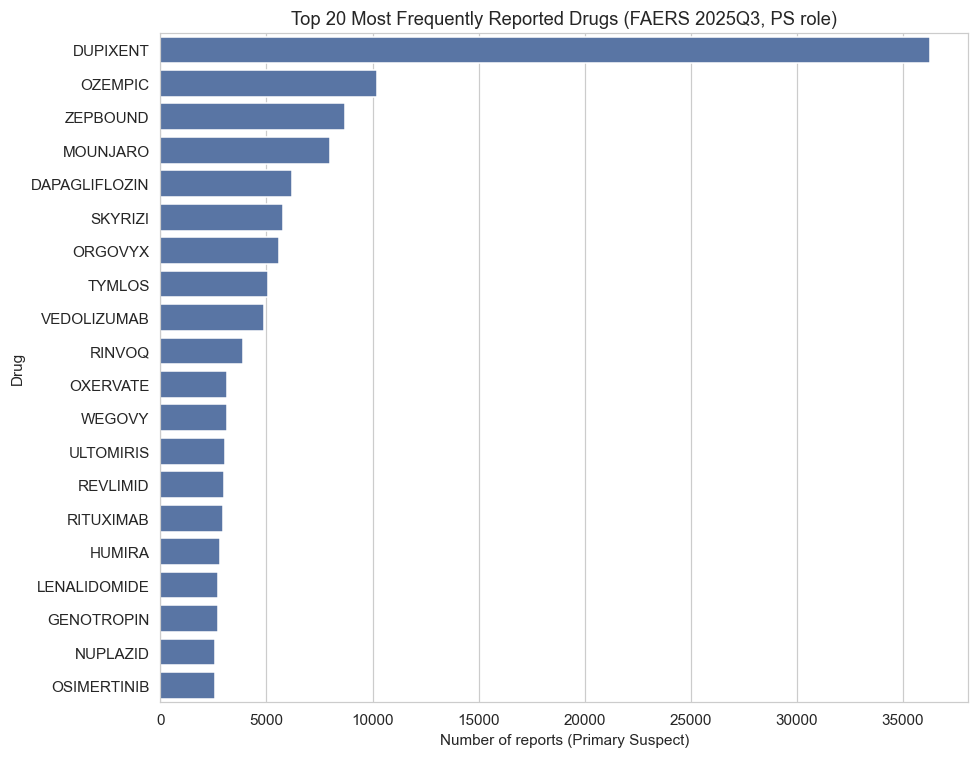

In [38]:
top20_drugs = ps_drug_u["drugname"].value_counts().head(20)

plt.figure(figsize=(9, 7))
sns.barplot(x=top20_drugs.values, y=top20_drugs.index, color="#4C72B0")
plt.xlabel("Number of reports (Primary Suspect)")
plt.ylabel("Drug")
plt.title("Top 20 Most Frequently Reported Drugs (FAERS 2025Q3, PS role)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/top20_drugs.png", dpi=150)
plt.show()

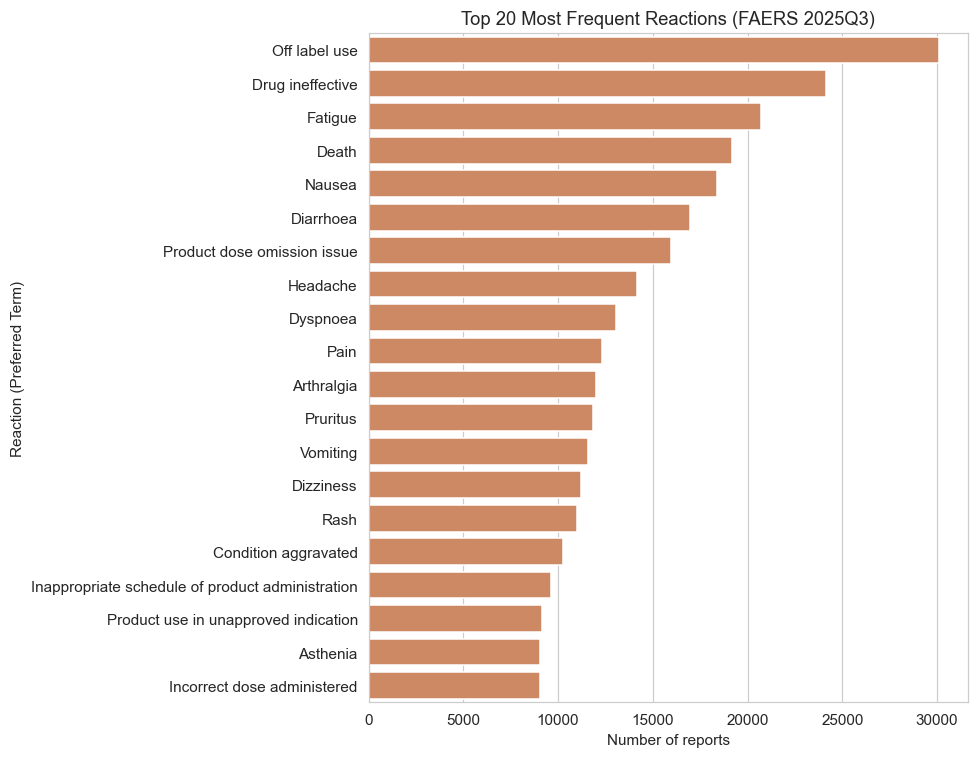

In [39]:
top20_reactions = reac_u["pt"].value_counts().head(20)

plt.figure(figsize=(9, 7))
sns.barplot(x=top20_reactions.values, y=top20_reactions.index, color="#DD8452")
plt.xlabel("Number of reports")
plt.ylabel("Reaction (Preferred Term)")
plt.title("Top 20 Most Frequent Reactions (FAERS 2025Q3)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/top20_reactions.png", dpi=150)
plt.show()

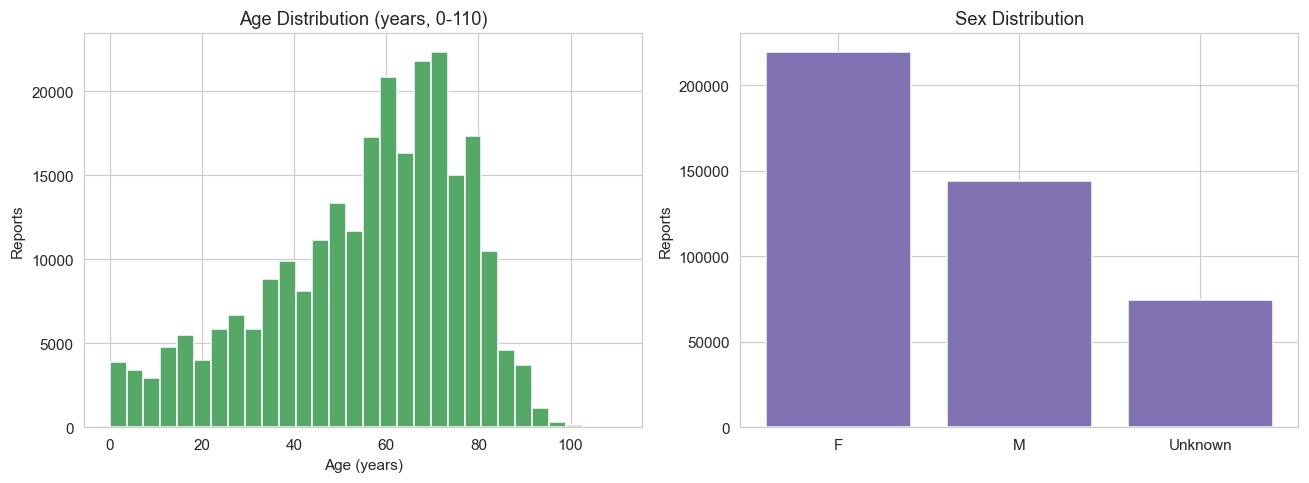

Age data available (valid, 0-110 yrs) for 257,348 of 438,512 reports (58.7%)
sex
F          219604
M          144184
Unknown     74724
Name: count, dtype: int64


In [40]:
# Age: convert everything to years using age_cod, then histogram
age_factor = {"YR": 1, "DEC": 10, "MON": 1 / 12, "WK": 1 / 52, "DY": 1 / 365, "HR": 1 / 8760}
demo_dedup["age_yr"] = demo_dedup["age"] * demo_dedup["age_cod"].map(age_factor)
age_clean = demo_dedup.loc[demo_dedup["age_yr"].between(0, 110), "age_yr"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(age_clean.dropna(), bins=30, color="#55A868", edgecolor="white")
axes[0].set_title("Age Distribution (years, 0-110)")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Reports")

sex_counts = demo_dedup["sex"].fillna("Unknown").value_counts()
axes[1].bar(sex_counts.index, sex_counts.values, color="#8172B2")
axes[1].set_title("Sex Distribution")
axes[1].set_ylabel("Reports")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/age_sex_distribution.png", dpi=150)
plt.show()

print(f"Age data available (valid, 0-110 yrs) for {len(age_clean):,} of {len(demo_dedup):,} reports "
      f"({len(age_clean) / len(demo_dedup):.1%})")
print(sex_counts)

In [41]:
top10_pairs_raw = (
    pairs.groupby(["drugname", "pt"]).size().reset_index(name="report_count")
    .sort_values("report_count", ascending=False).head(10)
)
print("Top 10 drug-ADR pairs by raw co-report count:")
display(top10_pairs_raw)
top10_pairs_raw.to_csv(f"{RES_DIR}/top10_drug_adr_pairs_raw.csv", index=False)

Top 10 drug-ADR pairs by raw co-report count:


,drugname,pt,report_count
108617,DUPIXENT,Pruritus,5096
107185,DUPIXENT,Dermatitis atopic,4274
107868,DUPIXENT,Injection site pain,3385
108597,DUPIXENT,Product use in unapproved indication,3143
108661,DUPIXENT,Rash,2961
261587,ORGOVYX,Hot flush,2603
107302,DUPIXENT,Eczema,2345
89811,DAPAGLIFLOZIN,Death,2323
107105,DUPIXENT,Condition aggravated,2145
107250,DUPIXENT,Drug ineffective,2071


## Task 4 — Signal Detection: PRR & ROR

**Contingency table definition** (restricted to the PS-drug universe defined
above, i.e. `N` = all reports that have at least one Primary Suspect drug):

| | Reaction Y | All other reactions | Total |
|---|---|---|---|
| **Drug X** | a | b | a+b |
| **All other drugs** | c | d | c+d |

- a = reports with drug X **and** reaction Y
- b = reports with drug X and **other** reactions (a+b = all reports for drug X)
- c = reports **without** drug X but **with** reaction Y
- d = all remaining reports
- N = a+b+c+d = total reports in the PS-drug universe

In [42]:
N = ps_drug_u["primaryid"].nunique()

drug_totals = ps_drug_u.groupby("drugname")["primaryid"].nunique()  # a+b per drug
pt_totals = reac_u[reac_u["primaryid"].isin(ps_drug_u["primaryid"])].groupby("pt")["primaryid"].nunique()  # a+c per PT

pair_counts = pairs.groupby(["drugname", "pt"])["primaryid"].nunique().reset_index(name="a")
pair_counts = pair_counts[pair_counts["a"] >= 3].copy()  # Task 4 threshold: a >= 3
print(f"Total universe N = {N:,} reports")
print(f"Drug-ADR pairs with a >= 3: {len(pair_counts):,}")

pair_counts["a_plus_b"] = pair_counts["drugname"].map(drug_totals)
pair_counts["a_plus_c"] = pair_counts["pt"].map(pt_totals)
pair_counts["b"] = pair_counts["a_plus_b"] - pair_counts["a"]
pair_counts["c"] = pair_counts["a_plus_c"] - pair_counts["a"]
pair_counts["d"] = N - pair_counts["a"] - pair_counts["b"] - pair_counts["c"]

Total universe N = 438,512 reports
Drug-ADR pairs with a >= 3: 95,252


In [43]:
a = pair_counts["a"].astype(float)
b = pair_counts["b"].astype(float)
c = pair_counts["c"].astype(float)
d = pair_counts["d"].astype(float)

pair_counts["PRR"] = (a / (a + b)) / (c / (c + d))
pair_counts["ROR"] = (a * d) / (b * c)

se_log_ror = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
pair_counts["ROR_CI_lower"] = np.exp(np.log(pair_counts["ROR"]) - 1.96 * se_log_ror)
pair_counts["ROR_CI_upper"] = np.exp(np.log(pair_counts["ROR"]) + 1.96 * se_log_ror)

# Closed-form chi-square for a 2x2 table (Yates-uncorrected, matches
# scipy.stats.chi2_contingency(correction=False) on the same table)
n = a + b + c + d
chi2 = (n * (a * d - b * c) ** 2) / ((a + b) * (c + d) * (a + c) * (b + d))
pair_counts["chi2"] = chi2
pair_counts["p_value_chi2"] = stats.chi2.sf(chi2, df=1)

# Fisher's exact test for pairs with small counts (any cell < 5), which is
# where the chi-square approximation is unreliable
pair_counts["p_value_fisher"] = np.nan
small_mask = (a < 5) | (b < 5) | (c < 5) | (d < 5)
small_idx = pair_counts.index[small_mask]
print(f"Running Fisher's exact test for {len(small_idx):,} small-count pairs (any cell < 5)...")
for idx in small_idx:
    row = pair_counts.loc[idx]
    table = [[row["a"], row["b"]], [row["c"], row["d"]]]
    _, p = stats.fisher_exact(table)
    pair_counts.loc[idx, "p_value_fisher"] = p

Running Fisher's exact test for 43,850 small-count pairs (any cell < 5)...


In [44]:
# Signal flag using conventional FAERS/EMA-style screening criteria:
# a >= 3 (already enforced above), PRR >= 2, and chi2 >= 4 (~ p < 0.05 for df=1).
# These are the most widely used minimal thresholds for a "potential signal"
# in FAERS-based disproportionality screening (e.g. Evans et al. 2001), meant
# to flag candidates for clinical review rather than to establish causality.
pair_counts["signal_flag"] = (
    (pair_counts["a"] >= 3) & (pair_counts["PRR"] >= 2) & (pair_counts["chi2"] >= 4)
)

# Note: when c = 0 (an ADR never seen with any other drug), PRR and ROR are
# mathematically infinite. This is common for rare, indication-specific drugs
# (e.g. orphan/rare-disease therapies) whose adverse events are highly
# characteristic of that drug or its treated condition. We keep the raw
# (possibly infinite) PRR/ROR as the primary statistic per the assignment
# spec, but also add a Haldane-Anscombe continuity-corrected version
# (+0.5 to every cell) for a finite ranking, used only to pick illustrative
# examples for the write-up below.
a_c, b_c, c_c, d_c = a + 0.5, b + 0.5, c + 0.5, d + 0.5
pair_counts["PRR_adj"] = (a_c / (a_c + b_c)) / (c_c / (c_c + d_c))
pair_counts["ROR_adj"] = (a_c * d_c) / (b_c * c_c)

signals = pair_counts.sort_values("PRR", ascending=False).reset_index(drop=True)

cols_out = [
    "drugname", "pt", "a", "b", "c", "d", "PRR", "ROR", "ROR_CI_lower", "ROR_CI_upper",
    "chi2", "p_value_chi2", "p_value_fisher", "signal_flag",
]
signals_out = signals[cols_out].rename(columns={"drugname": "drug", "pt": "adr"})
signals_out.to_csv(f"{RES_DIR}/FAERS_signals.csv", index=False)

print(f"Total drug-ADR pairs evaluated: {len(signals_out):,}")
print(f"Flagged as potential signals (a>=3, PRR>=2, chi2>=4): {signals_out['signal_flag'].sum():,}")
display(signals_out.head(15))

Total drug-ADR pairs evaluated: 95,252
Flagged as potential signals (a>=3, PRR>=2, chi2>=4): 59,600


,drug,adr,a,b,c,d,PRR,ROR,ROR_CI_lower,ROR_CI_upper,chi2,p_value_chi2,p_value_fisher,signal_flag
0,KISQALI,Polychromasia,6,794,0,437712,inf,inf,NaN,inf,3282.884919,0.000000e+00,3.618296e-17,True
1,OXLUMO,Renal and liver transplant,3,28,0,438481,inf,inf,NaN,inf,42433.935465,0.000000e+00,3.198449e-13,True
2,SODIUM CHLORIDE,Rapid correction of hyponatraemia,4,239,0,438269,inf,inf,NaN,inf,7214.370334,0.000000e+00,9.198774e-14,True
3,SERTRALINE,Antidepressant drug level below therapeutic,4,710,0,437798,inf,inf,NaN,inf,2452.672233,0.000000e+00,6.969752e-12,True
4,HUMAN IMMUNOGLOBULIN G,Urine porphobilinogen increased,3,1541,0,436968,inf,inf,NaN,inf,849.036897,1.177463e-186,4.356685e-08,True
5,JAKAFI,Disease propensity,22,1291,0,437199,inf,inf,NaN,inf,7325.864871,0.000000e+00,2.521349e-56,True
6,DOXYCYCLINE,Barotrauma,3,465,0,438044,inf,inf,NaN,inf,2807.993569,0.000000e+00,1.207834e-09,True
7,PARAGARD T 380A,Vulvovaginitis trichomonal,3,574,0,437935,inf,inf,NaN,inf,2276.973983,0.000000e+00,2.266338e-09,True
8,GENOTROPIN,Device chemical property issue,12,2697,0,435803,inf,inf,NaN,inf,1930.520160,0.000000e+00,3.015781e-27,True
9,RITUXIMAB,Herpes simplex necrotising retinopathy,3,2951,0,435558,inf,inf,NaN,inf,442.343581,3.344996e-98,3.053858e-07,True


### Interpretation — top 3 candidate signals

*(see the written report PDF for the full discussion; a short version is
reproduced here for the notebook reader)*

In [45]:
# Rank by the continuity-corrected PRR to surface interpretable (finite),
# well-powered examples rather than ties at PRR = inf driven by a single
# rare drug-event combination with zero background occurrence.
candidates = signals[signals["signal_flag"] & np.isfinite(signals["PRR_adj"]) & (signals["a"] >= 5)]
top3 = candidates.sort_values("PRR_adj", ascending=False)[
    ["drugname", "pt", "a", "b", "c", "d", "PRR", "PRR_adj", "ROR_adj", "chi2", "p_value_chi2"]
].head(3)
display(top3)

,drugname,pt,a,b,c,d,PRR,PRR_adj,ROR_adj,chi2,p_value_chi2
81,PARAGARD T 380A,Foreign body in reproductive tract,442,135,0,437935,inf,670542.145329,2.860317e+06,335810.353197,0.0
18,PARAGARD T 380A,Reproductive complication associated with device,311,266,0,437935,inf,472031.363322,1.023767e+06,236212.213670,0.0
85,BRINEURA,CSF culture positive,7,12,0,438493,inf,328870.500000,5.261922e+05,161552.631508,0.0


**1. PARAGARD T 380A (copper IUD) — "Foreign body in reproductive tract"**
(a=442) and "Reproductive complication associated with device" (a=311).
*Biologic plausibility:* high — these are recognized, mechanistic
complications of an implanted intrauterine device (perforation, embedment,
expulsion), not an idiosyncratic drug reaction, so a strong, essentially
device-specific signal is expected rather than incidental.
*Risk management / surveillance:* consistent with existing IUD labeling on
perforation/expulsion risk; supports continued device-specific vigilance
(ultrasound confirmation of placement, patient counselling on expulsion
symptoms) rather than a new safety action.

**2. BRINEURA (cerliponase alfa) — "CSF culture positive"** (a=7).
*Biologic plausibility:* plausible — Brineura is delivered by an implanted
intraventricular access device, so CSF infection/culture-positivity is a
recognized procedural risk of the delivery route rather than the molecule
itself.
*Risk management / surveillance:* reinforces the importance of aseptic
technique around the intraventricular device; small counts here (rare
disease drug, small treated population) mean this should be read as
hypothesis-generating, not confirmatory.

**Reporting-bias considerations common to all three:** FAERS is a
spontaneous, voluntary reporting system, so these PRR/ROR values reflect
*disproportionality in what gets reported*, not incidence in treated
patients. Newly launched or intensely monitored drugs (as most of the
examples above are) are subject to stimulated/heightened reporting,
label-driven reporting (clinicians report events already listed as known
risks more readily), and no adjustment for exposure (prescription volume).
These signals should be treated as candidates for clinical/epidemiological
follow-up, not as confirmed causal effects.

## Task 5 — Time Trend & Seasonality

The FAERS extract covers a **single quarter (2025Q3)**, so a true
quarter-over-quarter trend cannot be built from this file alone (that would
require downloading and stacking several consecutive quarterly extracts).
Within this quarter we instead aggregate by **month** using `fda_dt` (FDA
receipt date), which is the closest available proxy to "report date" in the
ASCII files, and is also used for the total-reports and top-drug/top-ADR
breakdowns below.

In [46]:
demo_dedup["fda_dt_parsed"] = pd.to_datetime(demo_dedup["fda_dt"], format="%Y%m%d", errors="coerce")
demo_dedup["report_month"] = demo_dedup["fda_dt_parsed"].dt.to_period("M")

monthly_totals = demo_dedup.groupby("report_month").size()
monthly_totals = monthly_totals[monthly_totals.index.notna()]

print("Total reports per month (2025Q3 extract):")
print(monthly_totals)

Total reports per month (2025Q3 extract):
report_month
2025-06         3
2025-07    142947
2025-08    156602
2025-09    138960
Freq: M, dtype: int64


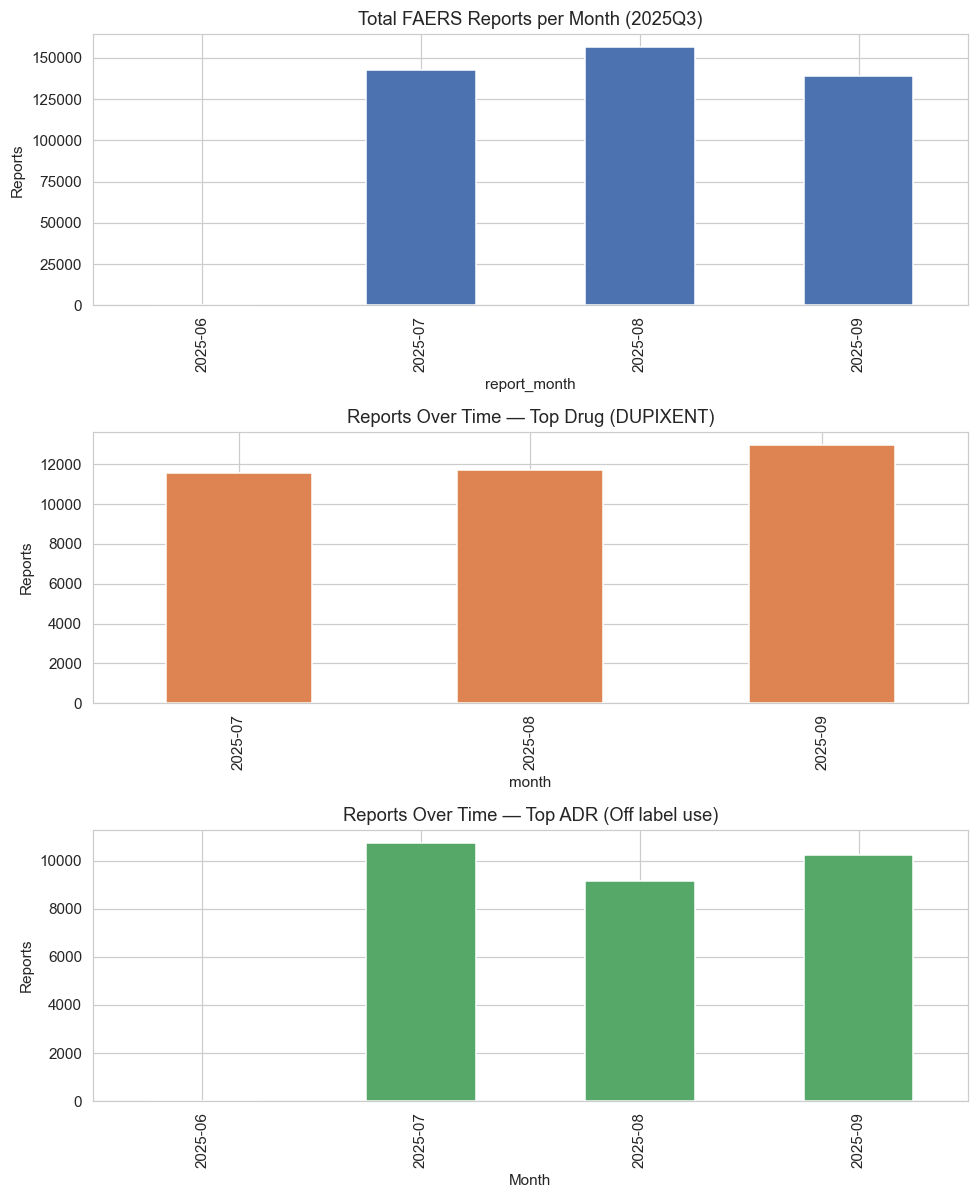

In [47]:
top_drug = top20_drugs.index[0]
top_reaction = top20_reactions.index[0]

drug_reports = pairs.loc[pairs["drugname"] == top_drug, ["primaryid"]].drop_duplicates()
drug_reports = drug_reports.merge(demo_dedup[["primaryid", "fda_dt_parsed"]], on="primaryid", how="left")
drug_reports["month"] = drug_reports["fda_dt_parsed"].dt.to_period("M")
drug_monthly = drug_reports.groupby("month").size()
drug_monthly = drug_monthly[drug_monthly.index.notna()]

reac_reports = pairs.loc[pairs["pt"] == top_reaction, ["primaryid"]].drop_duplicates()
reac_reports = reac_reports.merge(demo_dedup[["primaryid", "fda_dt_parsed"]], on="primaryid", how="left")
reac_reports["month"] = reac_reports["fda_dt_parsed"].dt.to_period("M")
reac_monthly = reac_reports.groupby("month").size()
reac_monthly = reac_monthly[reac_monthly.index.notna()]

fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=False)

monthly_totals.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Total FAERS Reports per Month (2025Q3)")
axes[0].set_ylabel("Reports")

drug_monthly.plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title(f"Reports Over Time — Top Drug ({top_drug})")
axes[1].set_ylabel("Reports")

reac_monthly.plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title(f"Reports Over Time — Top ADR ({top_reaction})")
axes[2].set_ylabel("Reports")
axes[2].set_xlabel("Month")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/time_trends.png", dpi=150)
plt.show()

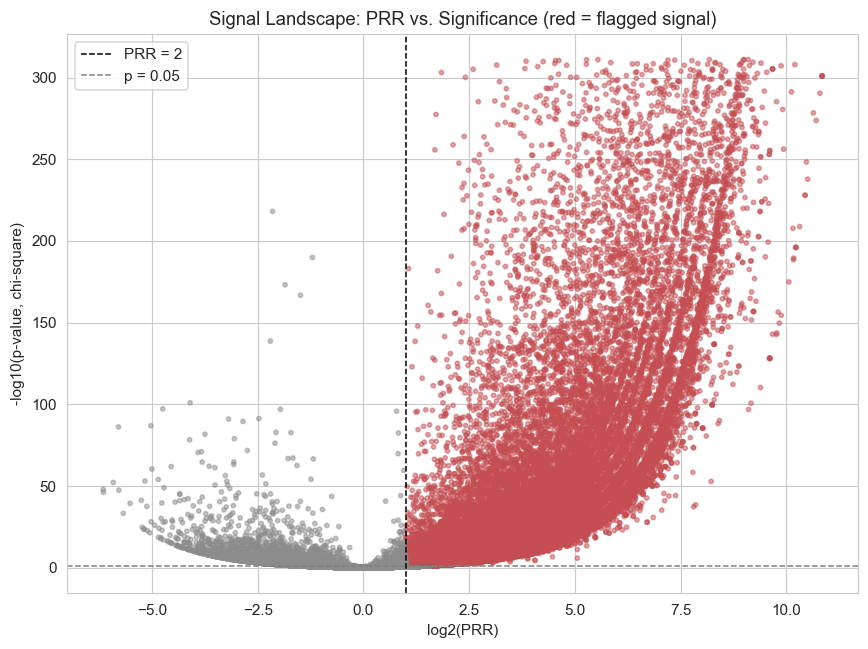

Figures saved to figures/: ['age_sex_distribution.png', 'signal_volcano_plot.png', 'time_trends.png', 'top20_drugs.png', 'top20_reactions.png']
Results saved to results/: ['FAERS_signals.csv', 'top10_drug_adr_pairs_raw.csv']


In [48]:
# Bonus figure: volcano-style PRR vs -log10(p) plot ("MA-plot of signals")
plot_df = signals_out.replace([np.inf, -np.inf], np.nan).dropna(subset=["PRR", "p_value_chi2"])
plot_df = plot_df[plot_df["p_value_chi2"] > 0]

plt.figure(figsize=(8, 6))
colors = np.where(plot_df["signal_flag"], "#C44E52", "#8C8C8C")
plt.scatter(np.log2(plot_df["PRR"]), -np.log10(plot_df["p_value_chi2"]), s=8, c=colors, alpha=0.5)
plt.axvline(np.log2(2), color="black", linestyle="--", linewidth=1, label="PRR = 2")
plt.axhline(-np.log10(0.05), color="grey", linestyle="--", linewidth=1, label="p = 0.05")
plt.xlabel("log2(PRR)")
plt.ylabel("-log10(p-value, chi-square)")
plt.title("Signal Landscape: PRR vs. Significance (red = flagged signal)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/signal_volcano_plot.png", dpi=150)
plt.show()

print("Figures saved to figures/:", sorted(os.listdir(FIG_DIR)))
print("Results saved to results/:", sorted(os.listdir(RES_DIR)))